In [11]:
import os
from enum import StrEnum
from typing import Optional, Literal

import polars as pl
from matplotlib import (
    pyplot as plt, 
    rcParams, 
    colors as mcolors, 
    patches as mpatches
)
from matplotlib.axes import Axes
import synapseclient

rcParams["font.family"] = "Arial"
rcParams["font.size"] = 7

In [2]:
# Jupyter server should be running from src/python
FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures"
)

GSEA_RESULTS_SYNID = "syn78432275"

In [3]:
os.makedirs(FIGURE_DIR, exist_ok=True)

In [4]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.14.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.14.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



In [5]:
results = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)

results

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_74487/3570276949.py:1: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  results = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)


[syn78432275]: Downloaded to /Users/dylan.ross/.synapseCache/383/178910383/gsea_results.parquet


Contrast,OmicsType,GeneSet,Term,NES,FDR q-val,Gene %,Tag %,leading_edge_size,gene_set_size,Lead_genes
str,str,str,str,f64,f64,f64,f64,i64,i64,str
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""MSigDB_Hallmark_2020""","""Myc Targets V1""",2.054229,0.0,23.99,57.731959,112,194,"""CDC45;PA2G4;RPS2;SRPK1;UBE2E1;…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Staphylococcus aureus infectio…",-3.573441,0.0,4.72,44.444444,20,45,"""FPR1;KRT9;KRT10;HLA-DMB;HLA-DM…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Graft-versus-host disease""",-2.616281,0.0,15.57,85.714286,18,21,"""HLA-DMB;HLA-DMA;HLA-G;HLA-DQA1…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Asthma""",-1.911691,0.003322,15.0,81.25,13,16,"""HLA-DMB;HLA-DMA;HLA-DQA1;HLA-D…"
"""Black_NPM1+/FLT3-ITD+_vs_White…","""Proteomics""","""KEGG_2021_Human""","""Dilated cardiomyopathy""",1.868212,0.023344,19.08,55.555556,15,27,"""ITGA2;ITGA2B;TGFB1;ITGB3;ATP2A…"
…,…,…,…,…,…,…,…,…,…,…
"""Black_NPM1+/FLT3-ITD-_vs_Black…","""Proteomics""","""Reactome_2022""","""Sema4D In Semaphorin Signaling…",-1.62075,0.03726,17.78,50.0,9,18,"""MYH11;MYH10;MYH14;RRAS;MYL6;AR…"
"""Black_NPM1+/FLT3-ITD-_vs_Black…","""Proteomics""","""Reactome_2022""","""Fanconi Anemia Pathway R-HSA-6…",-1.619351,0.037489,18.84,52.941176,9,17,"""USP1;CENPX;EME1;UBE2T;FANCD2;F…"
"""Black_NPM1+/FLT3-ITD-_vs_Black…","""Proteomics""","""Reactome_2022""","""RND2 GTPase Cycle R-HSA-969627…",-1.618669,0.037307,23.09,40.909091,9,22,"""PLXND1;CKAP4;ARHGAP5;GOLGA3;TF…"


In [12]:
class COLORS(StrEnum):
    LABEL_TEXT = "#FFF"
    EDGES = "#000"
    CMAP_MIN = "#44C"
    CMAP_MID = "#CCC"
    CMAP_MAX = "#C44"
    POP_BLACK = "#000"
    POP_WHITE = "#FFF"


# Custom colormap and normalizer centered around 0 in range [-N, +N]
N = 100
CMAP = mcolors.LinearSegmentedColormap.from_list(
    "custom_map", 
    [COLORS.CMAP_MIN, COLORS.CMAP_MID, COLORS.CMAP_MAX]
)
NORM = mcolors.Normalize(vmin=-N, vmax=N, clip=True)


TRI_INNER_PAD = 0.025
LW = 0.75
LABEL_SIZE = 7.5
TEXT_INSET = 0.3
MUT_RADIUS = 0.125
MUT_LABEL_SIZE = 5.5


def _get_mapped_color(count: int) -> str:
    return mcolors.to_hex(CMAP(NORM(count)))


def _plot_counts_triangles(
        ax: Axes,
        n_up: Optional[int],
        n_down: Optional[int],
):
    # setup
    ax.set_axis_off()
    ax.set_aspect("equal")
    ax.set_xlim((0 - TRI_INNER_PAD, 1 + TRI_INNER_PAD))
    ax.set_ylim((0 - TRI_INNER_PAD, 1 + TRI_INNER_PAD))

    if n_up is not None:
        # top triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (0, 1), (1, 1)],
            ec=COLORS.EDGES,
            fc=_get_mapped_color(n_up),
            lw=LW,
            joinstyle="round",
        ))
        # top label
        ax.text(
            TEXT_INSET, 1. - TEXT_INSET,
            f"{n_up:,}",
            fontsize=LABEL_SIZE,
            color=COLORS.LABEL_TEXT,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )
    else:
        # top triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (0, 1), (1, 1)],
            ec=COLORS.CMAP_MID,
            fc="none",
            lw=LW,
            joinstyle="round",
        ))
        # top label
        ax.text(
            TEXT_INSET, 1. - TEXT_INSET,
            "0",
            fontsize=LABEL_SIZE,
            color=COLORS.CMAP_MID,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )

    if n_down is not None:
        # bottom triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (1, 1), (1, 0)],
            ec=COLORS.EDGES,
            fc=_get_mapped_color(-n_down),
            lw=LW,
            joinstyle="round",
        ))
        # bottom label
        ax.text(
            1 - TEXT_INSET, TEXT_INSET,
            f"{n_down:,}",
            fontsize=LABEL_SIZE,
            color=COLORS.LABEL_TEXT,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )
    else:
        # bottom triangle
        ax.add_patch(mpatches.Polygon(
            [(0, 0), (1, 1), (1, 0)],
            ec=COLORS.CMAP_MID,
            fc="none",
            lw=LW,
            joinstyle="round",
        ))
        # bottom label
        ax.text(
            1 - TEXT_INSET, TEXT_INSET,
            "0",
            fontsize=LABEL_SIZE,
            color=COLORS.CMAP_MID,
            fontweight="bold",
            ha="center", va="center",
            rotation=45
        )


def _plot_comparison_metadata(
        ax: Axes,
        pop: Optional[Literal["Black", "White"]],
        top_npm1: bool,
        top_flt3: bool,
        bottom_npm1: bool,
        bottom_flt3: bool,

):
    # setup
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_aspect("equal")
    ax.set_xlim((0, 1))
    ax.set_ylim((0, 1))

    # box indicating population
    box_inset = 0.1
    box_height = 0.1
    fc = (
        {"Black": COLORS.POP_BLACK, "White": COLORS.POP_WHITE}[pop] 
        if pop is not None 
        else "none"
    )
    ax.add_patch(mpatches.Rectangle(
        (box_inset, 1 - box_inset - box_height),
        1 - 2 * box_inset, 
        box_height,
        ec=COLORS.EDGES,
        fc=fc,
        lw=LW,
        hatch="//////" if fc == "none" else None
    ))

    # mutations
    metadata_divider_x_inset = 0.1
    xmin = metadata_divider_x_inset
    xmax = 1 - metadata_divider_x_inset
    ymin = metadata_divider_x_inset
    divider_height = 0.5
    ymax = ymin + divider_height
    ax.plot(
        [xmin, xmax],
        [ymin, ymax],
        ls="--",
        lw=LW,
        c=COLORS.POP_BLACK,
    )

    dx = 0.1 
    dy = 0.2
    for point, flag, mut in zip(
        [
            (xmin + dx / 2, ymin + 1.5 * dy), 
            (xmin + 3 * dx, ymin + 2 * dy), 
            (xmax - dx / 2, ymax - 1.5 * dy), 
            (xmax - 3 * dx, ymax - 2 * dy)
        ],
        [top_npm1, top_flt3, bottom_flt3, bottom_npm1],
        "NFFN"
    ):
        ax.add_patch(mpatches.Circle(
            point,
            MUT_RADIUS,
            ec=COLORS.EDGES,
            fc=COLORS.EDGES if flag else COLORS.LABEL_TEXT,
            lw=LW
        ))
        ax.text(
            point[0], point[1] - 0.01,
            mut,
            fontsize=MUT_LABEL_SIZE,
            color=COLORS.LABEL_TEXT if flag else COLORS.EDGES,
            fontweight="bold",
            ha="center", va="center"
        )
    
    ax.set_xticks([])
    ax.set_yticks([])

In [15]:
def plot_sig_up_down_pathway_counts(
        results: pl.DataFrame, 
        figname: str
): 
    # key: (contrast, omics type, direction)
    # value: feature count
    counts = {
        tuple(k): v
        for *k, v
        in (
            results
            .with_columns(
                pl.when(pl.col("NES") > 0)
                .then(pl.lit("up"))
                .otherwise(pl.lit("down"))
                .alias("Direction")
            )
            .group_by("OmicsType", "Contrast", "Direction")
            .len()
            .sort("Contrast", "OmicsType", "Direction")
            .select("Contrast", "OmicsType", "Direction", "len")
            .iter_rows()
        )
    }

    SUBPLOT_PAD = 0.1
    SCALE = 0.55

    fig, axs = plt.subplots(
        figsize=(12 * SCALE, 3 * SCALE),
        ncols=12, nrows=3,
    )


    # first columns: comparison of white vs. black (within specific mutations)
    x = 0
    for mutations in [
        (False, False),
        (True, False),
        (False, True),
        (True, True),
    ]:
        comparison = (
            f"Black_"
            f"NPM1{'+' if mutations[0] else '-'}/"
            f"FLT3-ITD{'+' if mutations[1] else '-'}"
            f"_vs_White_"
            f"NPM1{'+' if mutations[0] else '-'}/"
            f"FLT3-ITD{'+' if mutations[1] else '-'}"
        )
        _plot_comparison_metadata(axs[0][x], None, *mutations, *mutations)
        for y, omics_data_type in enumerate(
                ["Transcriptomics", "Proteomics"], 
                start=1
            ):
                _plot_counts_triangles(
                    axs[y][x],
                    counts.get((comparison, omics_data_type, "up")),
                    counts.get((comparison, omics_data_type, "down")),
                    
                )
        # next column
        x += 1

    for mutations in [
        # NPM1 (top), FLT3-ITD (top), NPM1 (bottom), FLT3-ITD (bottom)
        (True, False, False, False),
        (False, True, False, False),
        (True, True, True, False),
        (True, True, False, True),
    ]:
        for pop in ["Black", "White"]:
            # metadata description
            _plot_comparison_metadata(axs[0][x], pop, *mutations)
            comparison = (
                f"{pop}_"
                f"NPM1{'+' if mutations[0] else '-'}/"
                f"FLT3-ITD{'+' if mutations[1] else '-'}"
                f"_vs_{pop}_"
                f"NPM1{'+' if mutations[2] else '-'}/"
                f"FLT3-ITD{'+' if mutations[3] else '-'}"
            )
            # triangles
            for y, omics_data_type in enumerate(
                ["Transcriptomics", "Proteomics"], 
                start=1
            ):
                _plot_counts_triangles(
                    axs[y][x],
                    counts.get((comparison, omics_data_type, "up")),
                    counts.get((comparison, omics_data_type, "down")),
                    
                )
            # next column
            x += 1

    fig.subplots_adjust(wspace=SUBPLOT_PAD, hspace=SUBPLOT_PAD)
    plt.savefig(
        figname,
        dpi=400,
        bbox_inches="tight",
        transparent=True
    )
    plt.show()
    plt.close()

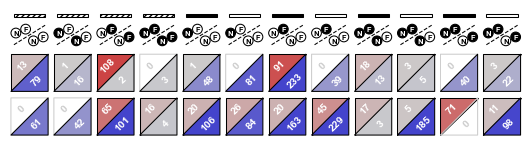

In [16]:
plot_sig_up_down_pathway_counts(
    results,
    os.path.join(FIGURE_DIR, "gsea_sig_pathway_counts.png")
)